This notebook ('diann_protein_group_abundance_cv.ipynb') reads and filters the main report from DIANN output (report.parquet), selects runs for defined conditions, and calculates the coefficient of variation (CV) of protein group abundances (PG.MaxLFQ) across replicates, restricted to protein groups quantified in every run across all conditions.
Results are exported as individual .csv files per flush mode together with violin plots visualizing the CV distributions per condition.

**Workflow overview:**

1. **Setup** – Import packages, set working directory, import custom `diann_main_report_filtering` module, enable autoreload, configure pandas display options.
2. **Define paths** – Set `input_dir` / `output_dir` for the dataset to process.
3. **Load report** – Read DIA-NN's `report.parquet` into a pandas DataFrame.
4. **FDR filtering** – Sequentially filter the main report at 1% precursor Q.Value (run-specific and global) and 1% global protein group Q.Value, plus a lenient Quantity.Quality cutoff (≥ 0.5).
5. **Run selection** – Define forward and reverse flush run lists per condition (pepmap, nanoshield_tht021_flip, direct_injection) and subset the filtered report into `main_report_pd_fil_for` / `main_report_pd_fil_rev`.
6. **Condition assignment & proteotypic filtering** – Map acquisition dates to condition names, then retain only proteotypic protein groups with a valid, non-zero PG.MaxLFQ value.
7. **Completeness filtering** – Retain only protein groups quantified in all replicates within each condition AND present in every condition (cross-condition completeness).
8. **CV calculation** – Compute mean, standard deviation, and CV of PG.MaxLFQ per protein group per condition; pivot to one CV column per condition and add percentage CV columns.
9. **cRAP removal** – Exclude protein groups containing "cRAP" in their name.
10. **Export & plot** – For each flush mode (forward, reverse), export the CV table as `.csv` and generate/save a violin plot of the CV (%) distribution per condition, with median values annotated.

In [1]:
# import relevant packages
import sys
import os
import inspect
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from textwrap import dedent
import seaborn as sns

# change working direction - point to where your notebooks (.ipynb) and python files (.py) are placed
new_cwd = Path("Z:/user/Dennis/trap_column_test/manuscript/diann_processing/jupyter_notebooks/github/")
os.chdir(new_cwd)
# verify new working directory
print("Current working directory:\n",os.getcwd())

# import custom functions
import diann_main_report_filtering as diann_filter

# auto reload of imported packages
%load_ext autoreload
%autoreload 2

# check where python is looking for path to resolve imports and where it actually loaded the packages from
print(f"This is where python is looking for packages:\n{sys.path}\n")

# change display settings for pandas dataframes
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

# set to back to default if needed
#pd.reset_option("display.max_columns")
#pd.reset_option("display.max_rows")
    
# check current working directory of this notebook
print("Current working directory:")
!pwd

Current working directory:
 Z:\user\Dennis\trap_column_test\manuscript\diann_processing\jupyter_notebooks\github
This is where python is looking for packages:
['C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\python313.zip', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\DLLs', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test', '', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages\\win32', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages\\win32\\lib', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages\\Pythonwin']

Current working directory:
/z/user/Dennis/t

In [2]:
# define input and output directories for each acquired dataset

input_dir = Path("Z:/user/Dennis/trap_column_test/manuscript/diann_processing/dataset_g_combined/")
output_dir = Path("Z:/user/Dennis/trap_column_test/manuscript/diann_processing/dataset_g_combined/github_test/protein_group_abuncance_cv/")

In [3]:
# read dianns main output parquet file as a pandas dataframe

# define input file name
input_file_name = "report.parquet"
# define input file path
input_file_path = input_dir / input_file_name
# read parquet file as pd dataframe
main_report_pd = pd.read_parquet(input_file_path, engine='pyarrow')
print("DIANN's parquet file was read in as a pandas dataframe.")

DIANN's parquet file was read in as a pandas dataframe.


In [4]:
# perform basic FDR filtering of loaded main report, "main_report_pd"

# filters sequentially, overwriting the variable to save memory
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd, column="Q.Value", cutoff=0.01, smaller_than=True, filter_proteotypic=False) # default precursor filtering at 1%, run-specific
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd_fil, column="Global.Q.Value", cutoff=0.01, smaller_than=True, filter_proteotypic=False) # precursor filtering at 1%, global
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd_fil, column="Global.PG.Q.Value", cutoff=0.01, smaller_than=True, filter_proteotypic=False) # protein group filtering at 1%, global
# lenient, retain the vast majority of IDs, drop only clearly bad ones - quality of precursor quantity, is it trustworthy
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd_fil, column="Quantity.Quality", cutoff=0.5, smaller_than=False, filter_proteotypic=False)
# reset index after filtering to maintain a clean sequence
main_report_pd_fil.reset_index(drop=True, inplace=True)
print("Dataframe was filtered successfully")

Dataframe was filtered successfully


In [5]:
# higher level conditions and run selection

# define selected runs
run_sel_for = [
  # pepmap - forward
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_1",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_2",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_3",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_4",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_5",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_6",
  # nanoshield tht021 flipped - forward
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_1",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_2",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_3",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_4",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_5",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_6",
  # direct injection
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_1",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_2",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_3",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_4",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_5",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_6", 
]

run_sel_rev = [
  # pepmap - reverse
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_1",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_2",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_3",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_4",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_5",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_6",
  # nanoshield tht021 flipped - reverse
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_1",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_2",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_3",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_4",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_5",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_6",
  # direct injection
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_1",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_2",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_3",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_4",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_5",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_6", 
]

# select runs from main report using exact matching for "Run" name - main_report_pd_fil_for is main dataframe used for all analyses below - forward
main_report_pd_fil_for = main_report_pd_fil[main_report_pd_fil["Run"].isin(run_sel_for)].copy()
print("Selection is done - forward")
# select runs from main report using exact matching for "Run" name - main_report_pd_fil_rev is main dataframe used for all analyses below - reverse
main_report_pd_fil_rev = main_report_pd_fil[main_report_pd_fil["Run"].isin(run_sel_rev)].copy()
print("Selection is done - reverse")

Selection is done - forward
Selection is done - reverse


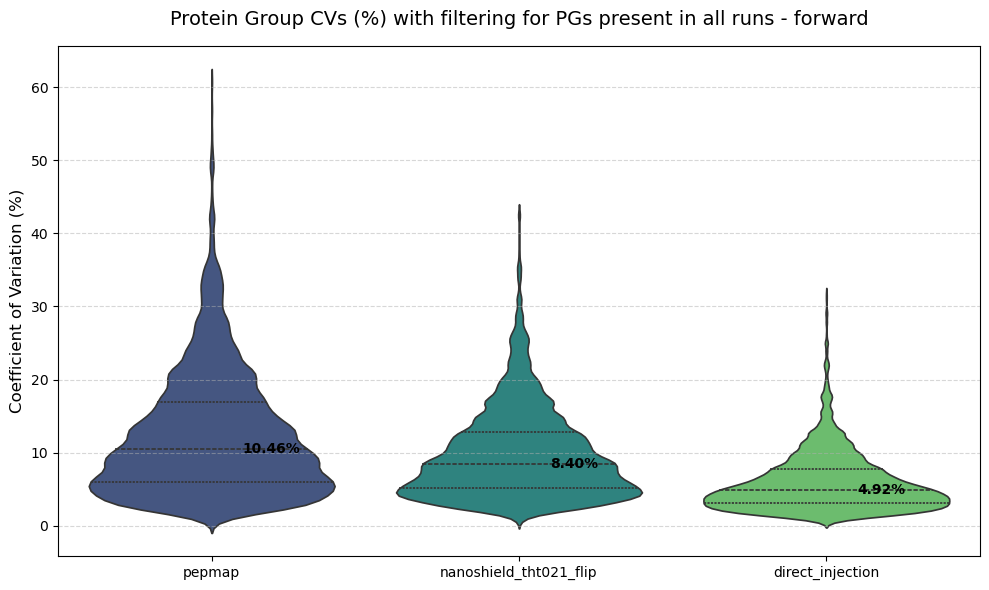

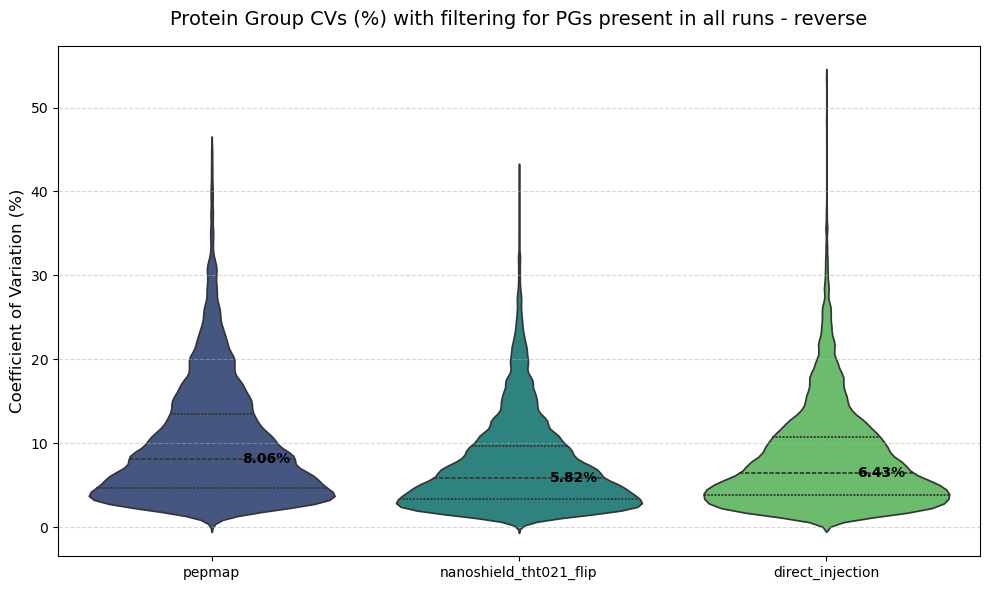

In [6]:
# assessing cv distribution for all quantified protein groups -
# filtering for protein groups present in all replicates within each condition AND present in all conditions
# (i.e. only protein groups quantified in every single run across all conditions are retained)

# copy main report
main_report_pd_fil_for_cv = main_report_pd_fil_for.copy()
main_report_pd_fil_rev_cv = main_report_pd_fil_rev.copy()
# create a mapping dictionary for the conditions
date_to_condition = {
    "20260911": "pepmap",
    "20260914": "nanoshield_tht021_flip",
    "20260916": "direct_injection"
}

# calculating cv values
# 1. extract the first 8 characters from the "Run" column (acquisition date) and map these dates to the condition names ("date_to_condition")
main_report_pd_fil_for_cv["Condition"] = (main_report_pd_fil_for_cv["Run"].astype(str).str[:8].map(date_to_condition))
main_report_pd_fil_rev_cv["Condition"] = (main_report_pd_fil_rev_cv["Run"].astype(str).str[:8].map(date_to_condition))

# 2. filter for protein groups identified and quantified using only proteotypic peptides
# and drop all rows that hold a value of zero or are missing entirely for PG.MaxLFQ column
main_report_pd_fil_for_cv = main_report_pd_fil_for_cv[main_report_pd_fil_for_cv["Proteotypic"] == 1]
main_report_pd_fil_for_cv = main_report_pd_fil_for_cv[(main_report_pd_fil_for_cv["PG.MaxLFQ"] != 0) & (main_report_pd_fil_for_cv["PG.MaxLFQ"].notna())]
main_report_pd_fil_rev_cv = main_report_pd_fil_rev_cv[main_report_pd_fil_rev_cv["Proteotypic"] == 1]
main_report_pd_fil_rev_cv = main_report_pd_fil_rev_cv[(main_report_pd_fil_rev_cv["PG.MaxLFQ"] != 0) & (main_report_pd_fil_rev_cv["PG.MaxLFQ"].notna())]

# 3. filter for protein groups quantified in ALL replicates WITHIN each condition,
# and additionally require the protein group to be complete in EVERY condition
# (so the same set of protein groups is compared across all conditions)
def filter_complete_per_condition(df):
    # required run count per condition (number of replicates for that condition)
    req_counts = df.groupby("Condition")["Run"].nunique()
    # count how many runs each (Condition, Protein.Group) pair was actually seen in
    pg_counts = df.groupby(["Condition", "Protein.Group"])["Run"].nunique().reset_index(name="n_runs")
    pg_counts["required"] = pg_counts["Condition"].map(req_counts)
    # keep only (Condition, Protein.Group) pairs that are complete within their own condition
    complete_pairs = pg_counts[pg_counts["n_runs"] == pg_counts["required"]]
    # count in how many conditions each protein group is complete
    pg_complete_in_all_conditions = complete_pairs.groupby("Protein.Group")["Condition"].nunique()
    n_conditions = df["Condition"].nunique()
    # keep only protein groups that are complete in every condition
    pg_cons = pg_complete_in_all_conditions[pg_complete_in_all_conditions == n_conditions].index
    return df[df["Protein.Group"].isin(pg_cons)].copy()

main_report_pd_fil_for_cv = filter_complete_per_condition(main_report_pd_fil_for_cv)
main_report_pd_fil_rev_cv = filter_complete_per_condition(main_report_pd_fil_rev_cv)

# 4. calculate mean and standard deviation for each protein group per condition
cv_stats_for = (main_report_pd_fil_for_cv.groupby(["Condition", "Protein.Group"])["PG.MaxLFQ"].agg(["std", "mean"]).reset_index())
cv_stats_for["CV"] = cv_stats_for["std"] / cv_stats_for["mean"]
cv_stats_rev = (main_report_pd_fil_rev_cv.groupby(["Condition", "Protein.Group"])["PG.MaxLFQ"].agg(["std", "mean"]).reset_index())
cv_stats_rev["CV"] = cv_stats_rev["std"] / cv_stats_rev["mean"]

# 5. pivot dataframe so each condition has its own column of cv values
df_protein_cv_for = cv_stats_for.pivot(index="Protein.Group", columns="Condition", values="CV").reset_index()
df_protein_cv_rev = cv_stats_rev.pivot(index="Protein.Group", columns="Condition", values="CV").reset_index()

# 6. add columns where the cv is expressed as a percentage
# both forward and reverse run selections include direct injection (per run_sel_for / run_sel_rev),
# so the same condition list applies to both
conditions = ["pepmap", "nanoshield_tht021_flip", "direct_injection"]

for cond in conditions:
    df_protein_cv_for[f"{cond}_cv_pct"] = df_protein_cv_for[cond] * 100
    df_protein_cv_rev[f"{cond}_cv_pct"] = df_protein_cv_rev[cond] * 100

# 7. create a copied dataframe removing protein groups containing "cRAP" in their name
# case=False ensures it catches variations like 'cRAP', 'crap', or 'CRAP'
df_protein_cv_for_nocrap = df_protein_cv_for[~df_protein_cv_for["Protein.Group"].str.contains("cRAP", case=False, na=False)].copy()
df_protein_cv_rev_nocrap = df_protein_cv_rev[~df_protein_cv_rev["Protein.Group"].str.contains("cRAP", case=False, na=False)].copy()

# 8. export cv values as .csv files
df_protein_cv_for_nocrap.to_csv(output_dir / 'cvs_per_run_filtering_forward.csv', index=False)
df_protein_cv_rev_nocrap.to_csv(output_dir / 'cvs_per_run_filtering_reverse.csv', index=False)


# visualizing cv distributions for each tested condition, i.e. trap columns
# for forward and reverse flush mode, filtered for protein groups present in all runs
plot_configs = [
    (df_protein_cv_for_nocrap, "forward", "with filtering for PGs present in all runs", "protein_group_cv_distribution_violin_with_filtering_forward.png"),
    (df_protein_cv_rev_nocrap, "reverse", "with filtering for PGs present in all runs", "protein_group_cv_distribution_violin_with_filtering_reverse.png"),
]

for df, flush_label, filter_label, file_name in plot_configs:
    # 1. melt the dataframe to long-form format using the percentage columns
    pct_columns = [f"{cond}_cv_pct" for cond in conditions]
    df_violin_plot = df.melt(
        id_vars="Protein.Group",
        value_vars=pct_columns,
        var_name="Condition",
        value_name="CV_Percentage",
    )
    # 2. clean up the condition names for clean x-axis labels
    df_violin_plot["Condition"] = df_violin_plot["Condition"].str.replace("_cv_pct", "")
    # drop rows with no CV value
    df_violin_plot = df_violin_plot.dropna(subset=["CV_Percentage"])
    # 3. build the actual visualization
    plt.figure(figsize=(10, 6))
    ax = sns.violinplot(
        data=df_violin_plot,
        x="Condition",
        y="CV_Percentage",
        palette="viridis",
        hue="Condition",  # assigned to hue to avoid future deprecation warnings
        legend=False,
        inner="quartile",  # draws dashed lines for the 25th, 50th (median), and 75th percentiles
        bw_adjust=0.5,  # adjusts smoothness of the violin density curves
    )
    # --- dynamic median Text Overlay Block ---
    x_categories = [t.get_text() for t in ax.get_xticklabels()]
    for idx, cat_name in enumerate(x_categories):
        # calculate the precise median value for this filtered dataset subset
        median_val = df_violin_plot[df_violin_plot["Condition"] == cat_name]["CV_Percentage"].median()
        # overlay the numeric string on the plot
        # x = idx + 0.1 shifts the label slightly right of the midline for better legibility
        plt.text(
            x=idx + 0.1,
            y=median_val,
            s=f"{median_val:.2f}%",
            color="black",
            weight="bold",
            fontsize=10,
            va="center",  # center vertical bounds directly on the median quartile line
        )
    # ----------------------------------------
    plt.title(
        f"Protein Group CVs (%) {filter_label} - {flush_label}",
        fontsize=14,
        pad=15,
    )
    # explicitly clear the x-axis title label text
    plt.xlabel("")
    plt.ylabel("Coefficient of Variation (%)", fontsize=12)
    # set visual limits based on typical high-quality DIA proteomic expectations
    plt.grid(True, linestyle="--", alpha=0.5, axis="y")
    plt.tight_layout()
    # 4. save the file at 600 DPI to the output directory prior to rendering
    save_path = os.path.join(output_dir, file_name)
    plt.savefig(save_path, dpi=600, bbox_inches="tight")
    # 5. display plot
    plt.show()